# Encoder Training

Defines and trains the VAE encoder/decoder stack over the cleaned features.

> Generated from `Lab2_multi_task_modal.ipynb`.

In [448]:
import pandas as pd
import numpy as np
import ast
import os
from sklearn.model_selection import train_test_split
from tqdm import tqdm
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import tensorflow as tf
import tensorflow.keras
import keras
from tensorflow.keras import layers
from keras.models import Sequential
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import plotly.io as plt_io
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
import plotly.express as px
import itertools
from sklearn.utils import class_weight
from tensorflow.keras.models import Model
import random
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, roc_curve, auc, classification_report
%matplotlib inline

## Creating Variational Autoencoder (VAE)

Intuition behind VAE: https://towardsdatascience.com/understanding-variational-autoencoders-vaes-f70510919f73

A variational autoencoder (VAE) is a generative model consisting of an encoder and a decoder. The encoder learns to map data from a high-dimensional input space to a low-dimensional latent space, and the corresponding decoder maps the latent space back to the input space. Unlike traditional autoencoders, VAEs uses variational inference to force a regularized distribution on the latent space. This is done so by modifying the loss function to include a KL divergence term. The KL divergence term is a measure of how different the latent space distribution is from a standard normal distribution. The KL divergence term is minimized by the VAE so the latent space distribution is as close to a standard normal distribution as possible. This is done so the latent space is smooth and distances between points in the latent space are meaningful. The VAE is trained by minimizing the sum of the reconstruction loss and the KL divergence term. In the simplest methods, the reconstruction loss is defined by either mean squared error or binary cross entropy.

In [449]:
# Construct VAE using PyTorch libraries

# Sampling function (reparameterization trick)
def sampling(z_mean, z_log_var):
    """
    We begin by performing the reparameterization trick standard within VAEs.
    Given the latent mean and log variance terms, we sample a latent vector z.

    It is standard practice to have the sampling layer use z = z_mean + exp(0.5 * z_log_var).
    However, in Eli's original code, the Sampling layer did z = z_mean + exp(z_log_var) * epsilon, where epsilon ~ N(0, I).
    We copy the equation Eli used in PyTorch terms.
    """
    # epsilon has the same shape as z_mean and is sampled from a standard normal distribution
    epsilon = torch.randn_like(z_mean)

    # as stated above, we copy Eli's behaviour
    z = z_mean + torch.exp(z_log_var) * epsilon
    return z


# VAE model wrapper
class VAE(nn.Module):
    """
    PyTorch version of the Keras VAE(keras.Model) wrapper.

    This class:
    - holds an encoder and decoder
    - defines the forward pass that:
        * encodes inputs into (z_mean, z_log_var)
        * samples z using the reparameterization trick
        * decodes z back to a reconstruction
    """

    def __init__(self, encoder, decoder):
        """
        Args:
            encoder: a nn.Module that takes x and returns (z_mean, z_log_var)
            decoder: a nn.Module that takes z and returns reconstruction
        """
        super().__init__()  # Initialize the parent nn.Module internals
        self.encoder = encoder  # Store the encoder network
        self.decoder = decoder  # Store the decoder network

    def forward(self, x):
        """
        Forward pass of the VAE (both encoder and decoder).

        Args:
            self: calls the model itself and gives VAE access to encoder, decoder, training, and parameters.
            x: tensor detailing (1) the number of songs in a given batch and (2) the number of variables in each song vector.

        Returns:
            reconstructed x generated by the decoder
            z_mean: latent mean, shape [batch_size, latent_dim]
            z_log_var: latent "log variance"-like term, shape [batch_size, latent_dim]
        """
        # Encoder job is to produce these parameters of the latent distribution
        z_mean, z_log_var = self.encoder(x)  # next we will code encoder to return these two tensors

        # Sample latent vector z using the reparameterization trick
        z = sampling(z_mean, z_log_var)

        # Decoder job is to reconstruct z back to the input space
        reconstruction = self.decoder(z)  # we will eventually code decoder to return this tensor

        return reconstruction, z_mean, z_log_var


# ---- VAE loss function (reconstruction + KL) ----
def vae_loss(data, reconstruction, z_mean, z_log_var):
    """
    Compute the VAE loss that matches the original Keras code:

    Total loss = reconstruction loss + KL divergence

    The original Keras code did:
        reconstruction_loss = binary_crossentropy(data_space_x, reconstructed_x)
        kl_term = 1 + z_log_var - z_mean^2 - exp(z_log_var)
        kl_loss = -5e-4 * mean(sum(kl_term, axis=1))
        total_loss = reconstruction_loss + kl_loss

    We copy this behavior below.
    """

    # Reconstruction loss (BCE)
    # F.mse_loss expects values in [0, 1] if using it directly on probabilities.
    # reduction = 'sum' sums over all elements in the batch; we then divide by batch size to get an average per sample.
    #recon_loss = F.mse_loss(reconstruction, data, reduction='sum')
    #recon_loss = recon_loss / data.size(0)

    #BCE version.
    #reconstruction = torch.clamp(reconstruction, 1e-7, 1 - 1e-7)
    #data = torch.clamp(data, 1e-7, 1 - 1e-7)
    recon_loss = F.binary_cross_entropy(reconstruction, data, reduction='sum')
    recon_loss = recon_loss / data.size(0)

    # KL divergence term
    kl_term = (1 + z_log_var - z_mean.pow(2) - torch.exp(z_log_var))

    # Sum over latent dimensions (dim=1), then average over batch
    kl_loss = torch.sum(kl_term, dim=1)
    kl_loss = torch.mean(kl_loss)

    # Scale by the same factor used in the Keras code (-5e-4)
    kl_loss = -5e-2 * kl_loss

    # Total loss
    total_loss = recon_loss + kl_loss

    return total_loss, recon_loss, kl_loss


# One training step
def train_one_batch(model, optimizer, batch_x, device="cpu"):
    """
    Perform a single training step on one batch of data.

    This function is the PyTorch version of Keras's custom train_step method:
    - runs the forward pass
    - computes total/reconstruction/KL losses
    - computes gradients
    - updates model parameters using the optimizer
    - returns scalar metrics

    Args:
        model: VAE instance
        optimizer: torch.optim.Optimizer (we use Adam)
        batch_x: input batch tensor, with shape: [batch_size, input_dim]
        device: "cpu" or "cuda" (GPU) string

    Returns:
        Python floats with keys: "loss", "reconstruction_loss", "kl_loss"
    """
    # Put model in training mode (enables dropout, etc.)
    model.train()
    # Move data to the chosen device (CPU/GPU)
    batch_x = batch_x.to(device)

    # Forward pass: get reconstruction and latent parameters
    reconstruction, z_mean, z_log_var = model(batch_x)

    # Compute total loss and its components
    total_loss, recon_loss, kl_loss = vae_loss(batch_x, reconstruction, z_mean, z_log_var)

    # Backpropagation
    optimizer.zero_grad()  # Clear old gradients
    total_loss.backward()  # Compute gradients with respect to model parameters
    optimizer.step()  # Update the parameters

    # Return metrics as Python values
    return {
        "loss": float(total_loss.item()),
        "reconstruction_loss": float(recon_loss.item()),
        "kl_loss": float(kl_loss.item()),
    }

#ORIGINAL CODE USING KERAS:
# from tensorflow.keras import losses

# class VAE(keras.Model):
#     def __init__(self, encoder, decoder, **kwargs):
#         super().__init__(**kwargs)
#         self.encoder = encoder
#         self.decoder = decoder
#         self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
#         self.reconstruction_loss_tracker = keras.metrics.Mean(
#             name="reconstruction_loss"
#         )
#         self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    # @property
    # def metrics(self):
    #     return [
    #         self.total_loss_tracker,
    #         self.reconstruction_loss_tracker,
    #         self.kl_loss_tracker,
    #     ]
    # def train_step(self, data):
    #
    #     with tf.GradientTape() as tape:
    #         z_mean, z_log_var, z = self.encoder(data)
    #         reconstruction = self.decoder(z)
    #         # reconstruction_loss = tf.reduce_mean(
    #         #     tf.reduce_sum(
    #         #         keras.losses.mean_squared_error(data, reconstruction), axis=None
    #         #     )
    #         # )
    #         reconstruction_loss = losses.binary_crossentropy(data, reconstruction)
    #         #experiment with assessing a lambda value to the kl_loss
    #         kl_loss = (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
    #         kl_loss = -5e-4 * tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
    #         total_loss = reconstruction_loss + kl_loss
    #     grads = tape.gradient(total_loss, self.trainable_weights)
    #     self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
    #     self.total_loss_tracker.update_state(total_loss)
    #     self.reconstruction_loss_tracker.update_state(reconstruction_loss)
    #     self.kl_loss_tracker.update_state(kl_loss)
    #     return {
    #         "loss": self.total_loss_tracker.result(),
    #         "reconstruction_loss": self.reconstruction_loss_tracker.result(),
    #         "kl_loss": self.kl_loss_tracker.result(),
    #     }

# class Sampling(layers.Layer):
#     """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""
#
#     def call(self, inputs):
#         z_mean, z_log_var = inputs
#         batch = tf.shape(z_mean)[0]
#         dim = tf.shape(z_mean)[1]
#         epsilon = tf.keras.backend.random_normal(shape=(batch, dim))
#         return z_mean + tf.exp(z_log_var) * epsilon

Before creating my embedding, I will perform a train test split on my data. This way I can evaluate my VAE and overall model with songs that were not included in embedding matrix.

In [450]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import os

path = '/Users/lucasmusselman/Documents/GitHub/Capstone_Playlist_Creator/data/cleaned_songs_with_groups.csv'
print(os.path.exists(path))

#define songs_df
songs_df = pd.read_csv('/Users/lucasmusselman/Documents/GitHub/Capstone_Playlist_Creator/data/cleaned_songs_with_groups.csv')

print(songs_df.columns)

#split the data into train and test with genre_group as the label
X_train_embedding, X_test_embedding, y_train_embedding, y_test_embedding = train_test_split(songs_df.drop(columns=['genre_group']), songs_df['genre_group'], test_size=0.2, random_state=42, stratify=songs_df['genre_group'])

#preprocessing first
ohe = OneHotEncoder()
scaler = MinMaxScaler(feature_range=(0, 1))

#separate into numerical and categorical features
X_train_embedding_num = X_train_embedding.drop(columns=['key', 'mode'])

X_test_embedding_num = X_test_embedding.drop(columns=['key', 'mode'])

#one-hot encode the key label
train_key = ohe.fit_transform(X_train_embedding['key'].values.reshape(-1, 1)).toarray()
test_key = ohe.transform(X_test_embedding['key'].values.reshape(-1, 1)).toarray()

train_mode = X_train_embedding['mode'].values.reshape(-1, 1)
test_mode = X_test_embedding['mode'].values.reshape(-1, 1)

#creating categorical dataframe which combines the one-hot encoded key and the mode
X_train_embedding_cat = np.concatenate((train_key,train_mode), axis=1)
X_test_embedding_cat = np.concatenate((test_key,test_mode), axis=1)

#standardizing the numerical features
X_train_embedding_num = scaler.fit_transform(X_train_embedding_num)
X_test_embedding_num = scaler.transform(X_test_embedding_num)

#concatenate the one-hot encoded key and the numerical features
X_train_embedding = np.concatenate((X_train_embedding_num, X_train_embedding_cat), axis=1)
X_test_embedding = np.concatenate((X_test_embedding_num, X_test_embedding_cat), axis=1)

#print train and test shapes
print(X_train_embedding.shape)
print(X_test_embedding.shape)


True
Index(['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'artist_pop', 'track_pop', 'genre_group'],
      dtype='object')
(25760, 24)
(6440, 24)


In [451]:
#print the train embedding using pandas
pd.DataFrame(X_train_embedding).head()

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
0,0.556575,0.498498,0.860020,0.028482,0.548193,0.000000,0.1150,0.236710,0.580268,0.50,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.553517,0.801802,0.898799,0.159044,0.121486,0.000005,0.4980,0.537613,0.419522,0.45,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.581040,0.763764,0.890020,0.059563,0.086044,0.000003,0.0932,0.431294,0.684405,0.64,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.910296,0.700701,0.844534,0.267152,0.162651,0.000000,0.7700,0.751254,0.519989,0.46,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.506626,0.540541,0.869149,0.134096,0.329317,0.000000,0.1950,0.695085,0.553888,0.53,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### Encoder

In [452]:
# Maps input song features -> hidden layers -> (z_mean, z_log_var)

latent_dim = 12
input_dim = X_train_embedding.shape[1]   # number of features per song

class Encoder(nn.Module):
    """
    Encoder network:
    input_dim -> 19 (ReLU) -> 15 (ReLU) -> z_mean (12), z_log_var (12)
    """

    def __init__(self, input_dim, latent_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 19)  # first hidden layer
        self.fc2 = nn.Linear(19, 15)  # second hidden layer
        self.z_mean = nn.Linear(15, latent_dim)
        self.z_log_var = nn.Linear(15, latent_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        z_mean = self.z_mean(x)
        z_log_var = self.z_log_var(x)
        return z_mean, z_log_var

# create encoder instance
encoder = Encoder(input_dim=input_dim, latent_dim=latent_dim)


# original code:
# latent_dim = 12
# encoder_inputs = keras.Input(shape=(X_train_embedding.shape[1],))
# x =layers.Dense(19, activation="relu")(encoder_inputs)
# x = layers.Dense(15, activation="relu")(x)
# z_mean = layers.Dense(latent_dim, name="z_mean")(x)
# z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
# z = Sampling()([z_mean, z_log_var])
# encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
# encoder.summary()

### Decoder

In [453]:
# Maps latent vector z -> hidden layers -> reconstructed song features

class Decoder(nn.Module):
    """
    Decoder network:
    latent_dim -> 15 (ReLU) -> 19 (ReLU) -> input_dim (tanh)
    """

    def __init__(self, latent_dim, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(latent_dim, 15)
        self.fc2 = nn.Linear(15, 19)
        self.out = nn.Linear(19, input_dim)
        #Maybe?: self.out = nn.Sigmoid()

    def forward(self, z):
        x = F.relu(self.fc1(z))
        x = F.relu(self.fc2(x))
        x = self.out(x)
        x = torch.sigmoid(x)  # uses tanh function as per Eli's code
        return x

# create decoder instance
decoder = Decoder(latent_dim=latent_dim, input_dim=input_dim)

# original code:
# latent_inputs = keras.Input(shape=(latent_dim,))
# x = layers.Dense(15, activation="relu")(latent_inputs)
# x = layers.Dense(19, activation="relu")(x)
# decoder_outputs = layers.Dense(X_train_embedding.shape[1], activation="tanh")(x)
# decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")
# decoder.summary()

### VAE Training

In [454]:
from torch.utils.data import TensorDataset, DataLoader

# Wrap encoder and decoder in the VAE wrapper as previously defined
model = VAE(encoder, decoder)

# Choose device (GPU if available, else CPU)
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

# Convert training data from numpy to PyTorch tensor
X_train_tensor = torch.from_numpy(X_train_embedding).float()

# DataLoader for batching and shuffling
train_dataset = TensorDataset(X_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Adam optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Train for 100 epochs
num_epochs = 100

total_losses = []
recon_losses = []
kl_losses = []

for epoch in range(num_epochs):
    epoch_loss = 0.0
    epoch_recon = 0.0
    epoch_kl = 0.0
    count = 0
    for (batch_x,) in train_loader:      # each batch_x: [batch_size, input_dim]
        metrics = train_one_batch(model, optimizer, batch_x, device=device)
        epoch_loss += metrics["loss"]
        epoch_recon += metrics["reconstruction_loss"]
        epoch_kl += metrics["kl_loss"]
        count += 1

    avg_loss = epoch_loss / len(train_loader)
    total_losses.append(epoch_loss / count)
    recon_losses.append(epoch_recon / count)
    kl_losses.append(epoch_kl / count)
    print(
        f"Epoch {epoch+1:03d} | avg_loss={avg_loss:.4f} "
        f"(last batch: recon={metrics['reconstruction_loss']:.4f}, "
        f"kl={metrics['kl_loss']:.4f})"
    )

# original code:
# instantiate and run the VAE model
# vae = VAE(encoder, decoder)
# vae.compile(optimizer=keras.optimizers.Adam())
# vae.fit(X_train_embedding, epochs=100, batch_size=32, shuffle=True)


Epoch 001 | avg_loss=10.4582 (last batch: recon=9.2299, kl=0.2370)
Epoch 002 | avg_loss=8.6431 (last batch: recon=7.8353, kl=0.3866)
Epoch 003 | avg_loss=7.5587 (last batch: recon=6.9651, kl=0.4965)
Epoch 004 | avg_loss=6.9063 (last batch: recon=6.3553, kl=0.4607)
Epoch 005 | avg_loss=6.6785 (last batch: recon=6.0158, kl=0.3962)
Epoch 006 | avg_loss=6.5714 (last batch: recon=6.2163, kl=0.4156)
Epoch 007 | avg_loss=6.4895 (last batch: recon=6.0716, kl=0.3950)
Epoch 008 | avg_loss=6.3962 (last batch: recon=6.2753, kl=0.4289)
Epoch 009 | avg_loss=6.3065 (last batch: recon=6.1169, kl=0.3901)
Epoch 010 | avg_loss=6.2526 (last batch: recon=6.0773, kl=0.3947)
Epoch 011 | avg_loss=6.2074 (last batch: recon=5.7555, kl=0.4262)
Epoch 012 | avg_loss=6.1826 (last batch: recon=5.9303, kl=0.3882)
Epoch 013 | avg_loss=6.1626 (last batch: recon=6.0911, kl=0.3642)
Epoch 014 | avg_loss=6.1488 (last batch: recon=5.6598, kl=0.3716)
Epoch 015 | avg_loss=6.1421 (last batch: recon=5.6542, kl=0.3634)
Epoch 016

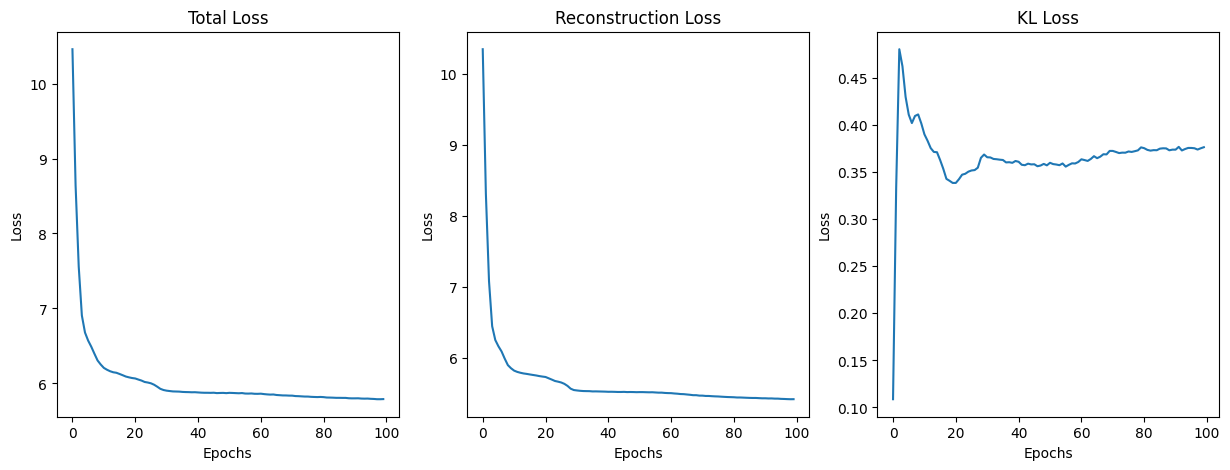

In [455]:
#plot the loss, reconstruction loss, and KL loss 3 in separate plots side by side
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.plot(total_losses)
plt.title('Total Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.subplot(1, 3, 2)
plt.plot(recon_losses)
plt.title('Reconstruction Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.subplot(1, 3, 3)
plt.plot(kl_losses)
plt.title('KL Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()

In [456]:
import torch

encoder.eval()
with torch.no_grad():
    X_train_tensor = torch.from_numpy(X_train_embedding).float().to(device)
    z_mean, z_log_var = encoder(X_train_tensor)
    latent_space = z_mean.cpu().numpy()

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(latent_space)

# Convert the data to a pandas DataFrame
df = pd.DataFrame({
    'pca0': X_train_pca[:, 0],
    'pca1': X_train_pca[:, 1],
    'genre_group': y_train_embedding
})

#Original code line: df = pd.DataFrame({'pca0': X_train_pca[:, 0], 'pca1': X_train_pca[:, 1], 'genre_group': y_train_embedding})

# Create a scatter plot using Plotly
fig = px.scatter(df, x='pca0', y='pca1', color='genre_group')

# Add labels and adjust the layout
fig.update_layout(
    title='PCA Latent Space Visualization',
    xaxis_title='pca0',
    yaxis_title='pca1',
    legend_title='Genre Group'
)

# Display the plot
fig.show()

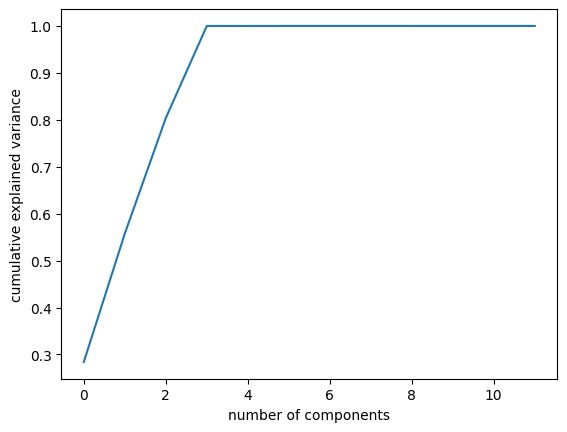

In [457]:
# create a scree plot to see how many components to keep
pca = PCA()
pca.fit(latent_space)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.show()


Scree plot to visualize the variance explained by each latent dimension, this is a good way to determine the number of latent dimensions to use.

